In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/elifsudayi/food-recipe-finder.git
%cd food-recipe-finder
!pip install -q -r requirements.txt
!mkdir -p /content/drive/MyDrive/swe015

Mounted at /content/drive
Cloning into 'food-recipe-finder'...
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 19 (delta 5), reused 19 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (19/19), 4.45 KiB | 2.23 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/food-recipe-finder
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import sys; sys.path.append(".")
from src.data.make_food10 import download_food101, build_subset

food_dir = download_food101("/content/food101_raw")
print(food_dir)

100%|██████████| 5.00G/5.00G [05:54<00:00, 14.1MB/s]


/content/food101_raw/food-101


In [ ]:
rows = build_subset(food_dir, "/content/food10", "results/splits.csv")
print(len(rows), "files copied")

10000 files copied


In [ ]:
!tar -cf /content/drive/MyDrive/swe015/food10.tar -C /content food10
!cp results/splits.csv /content/drive/MyDrive/swe015/splits.csv
!ls -lh /content/drive/MyDrive/swe015/

total 504M
-rw------- 1 root root 503M Nov 17 23:54 food10.tar
-rw------- 1 root root 286K Nov 17 23:54 splits.csv


In [ ]:
import pandas as pd
from pathlib import Path
from PIL import Image

df = pd.read_csv("results/splits.csv")
print(df.groupby(["split"]).size(), "\n")
print(df.pivot_table(index="class", columns="split", values="filename", aggfunc="count"))

bad, sizes = [], []
for p in Path("/content/food10").rglob("*.jpg"):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            sizes.append(im.size)
    except Exception as e:
        bad.append((p, e))
print("\ncorrupted file:", len(bad))
print("min/max width:", min(s[0] for s in sizes), max(s[0] for s in sizes))
print("min/max height:", min(s[1] for s in sizes), max(s[1] for s in sizes))

split
test     2500
train    6500
val      1000
dtype: int64 

split                test  train  val
class                                
caesar_salad          250    650  100
chicken_curry         250    650  100
french_fries          250    650  100
hamburger             250    650  100
ice_cream             250    650  100
omelette              250    650  100
pancakes              250    650  100
pizza                 250    650  100
spaghetti_carbonara   250    650  100
sushi                 250    650  100

corrupted file: 0
min/max width: 287 512
min/max height: 210 512


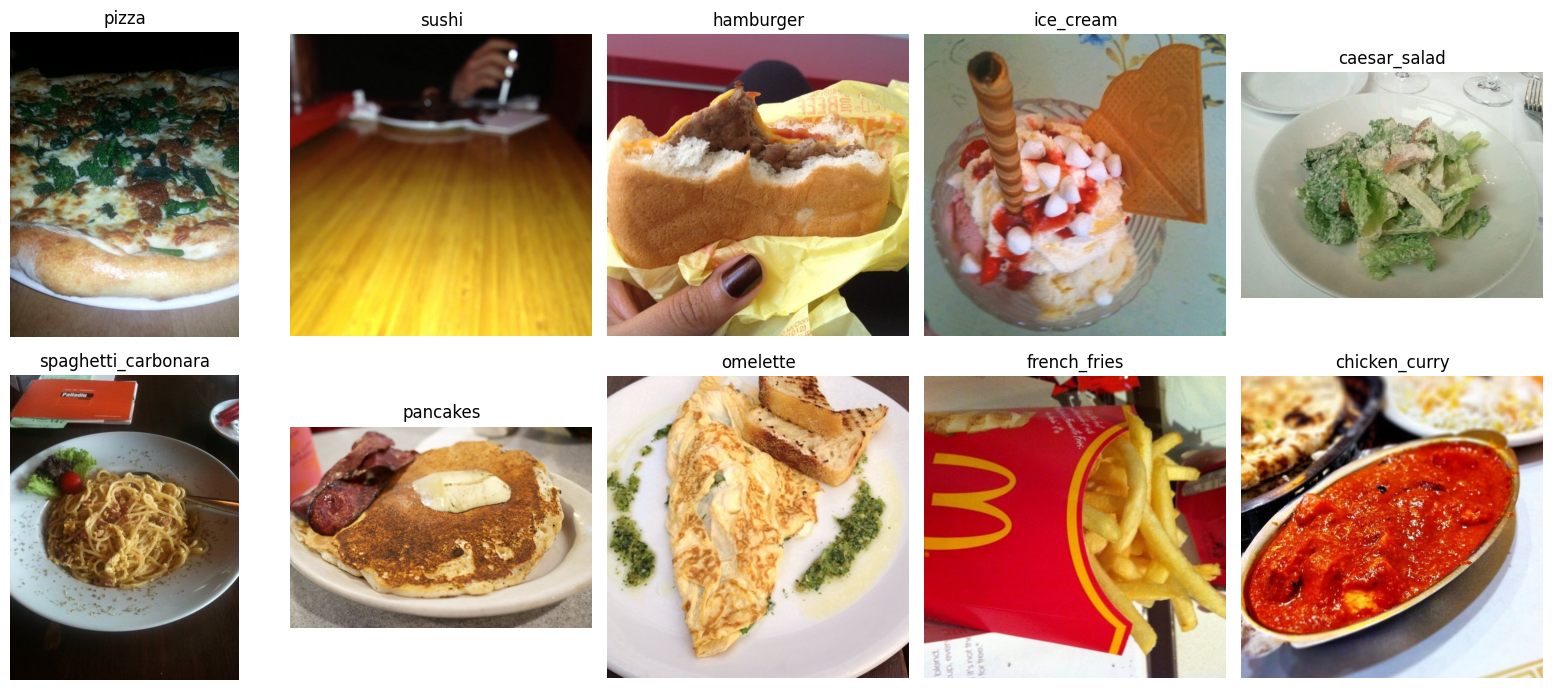

In [ ]:
import matplotlib.pyplot as plt
from src.config import CLASSES

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, cls in zip(axes.ravel(), CLASSES):
    p = next(Path(f"/content/food10/train/{cls}").glob("*.jpg"))
    ax.imshow(Image.open(p)); ax.set_title(cls); ax.axis("off")
plt.tight_layout(); plt.show()